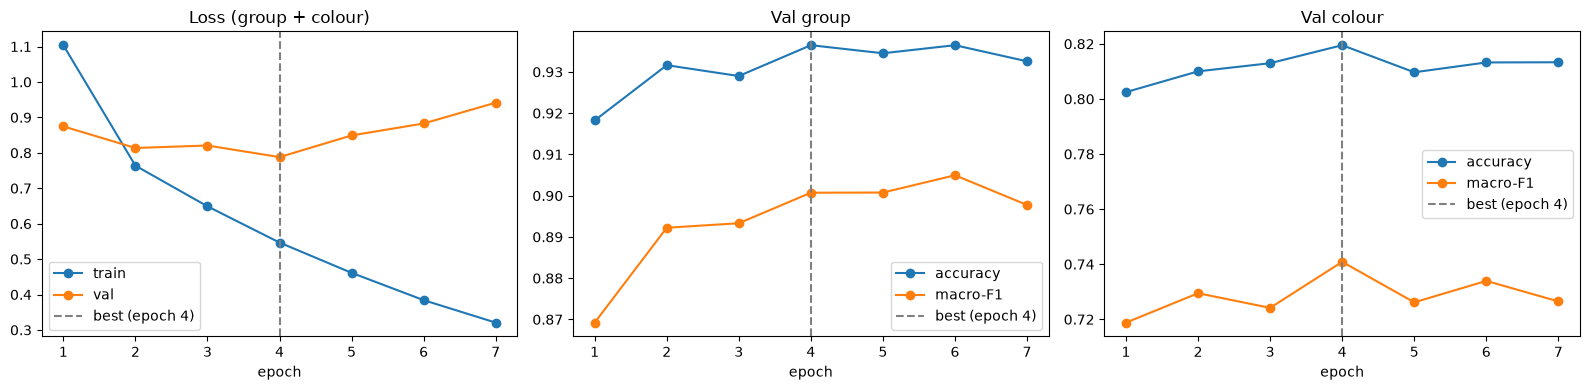

In [1]:
import sys
sys.path.append("..")        # lets us import "src.data.images"
sys.path.append("../src")    # lets train_finetune.py's own "from data.images" import work

import json
import numpy as np
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from src.data.images import ProductImages, class_lists
from train_finetune import MultiHeadResNet

device = "cuda" if torch.cuda.is_available() else "cpu"
groups, colours = class_lists()

hist = json.load(open("../runs/finetune_history.json"))
ep = [h["epoch"] for h in hist]
best = min(hist, key=lambda h: h["val_loss"])["epoch"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(ep, [h["train_loss"] for h in hist], "o-", label="train")
axes[0].plot(ep, [h["val_loss"] for h in hist], "o-", label="val")
axes[0].set_title("Loss (group + colour)")
for ax, task in zip(axes[1:], ["group", "colour"]):
    ax.plot(ep, [h[f"val_{task}_acc"] for h in hist], "o-", label="accuracy")
    ax.plot(ep, [h[f"val_{task}_f1"] for h in hist], "o-", label="macro-F1")
    ax.set_title(f"Val {task}")
for ax in axes:
    ax.axvline(best, color="grey", ls="--", label=f"best (epoch {best})")
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/finetune_curves.png", dpi=150)
plt.show()

In [2]:
model = MultiHeadResNet().to(device)
model.load_state_dict(torch.load("../runs/finetuned_resnet50.pt", map_location=device))
model.eval()

val_ds = ProductImages("val")
val_dl = DataLoader(val_ds, batch_size=128, shuffle=False, num_workers=2)

P_g, P_c = [], []
with torch.no_grad():
    for x, _, _ in val_dl:
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=(device == "cuda")):
            out_g, out_c = model(x.to(device))
        P_g.append(out_g.float().softmax(dim=1).cpu())
        P_c.append(out_c.float().softmax(dim=1).cpu())

P_g, P_c = torch.cat(P_g).numpy(), torch.cat(P_c).numpy()
y_g, y_c = np.array(val_ds.y_group), np.array(val_ds.y_colour)
pred_g, pred_c = P_g.argmax(1), P_c.argmax(1)
print(f"Val: {len(y_g):,} images | group acc {(pred_g == y_g).mean():.3f} | colour acc {(pred_c == y_c).mean():.3f}")

Val: 14,859 images | group acc 0.936 | colour acc 0.820


In [3]:
from sklearn.metrics import classification_report

print("PRODUCT GROUP")
print(classification_report(y_g, pred_g, target_names=groups, digits=3))
print("COLOUR")
print(classification_report(y_c, pred_c, target_names=colours, digits=3))

PRODUCT GROUP
                    precision    recall  f1-score   support

       Accessories      0.949     0.966     0.958      1565
 Garment Full body      0.840     0.901     0.870      1881
Garment Lower body      0.969     0.946     0.957      2795
Garment Upper body      0.957     0.957     0.957      6047
         Nightwear      0.806     0.600     0.688       270
             Shoes      0.976     0.978     0.977       735
    Socks & Tights      0.947     0.931     0.939       346
          Swimwear      0.849     0.851     0.850       444
         Underwear      0.927     0.896     0.911       776

          accuracy                          0.936     14859
         macro avg      0.913     0.892     0.901     14859
      weighted avg      0.937     0.936     0.936     14859

COLOUR
              precision    recall  f1-score   support

       Beige      0.679     0.717     0.698       809
       Black      0.906     0.908     0.907      3151
        Blue      0.899     0.905

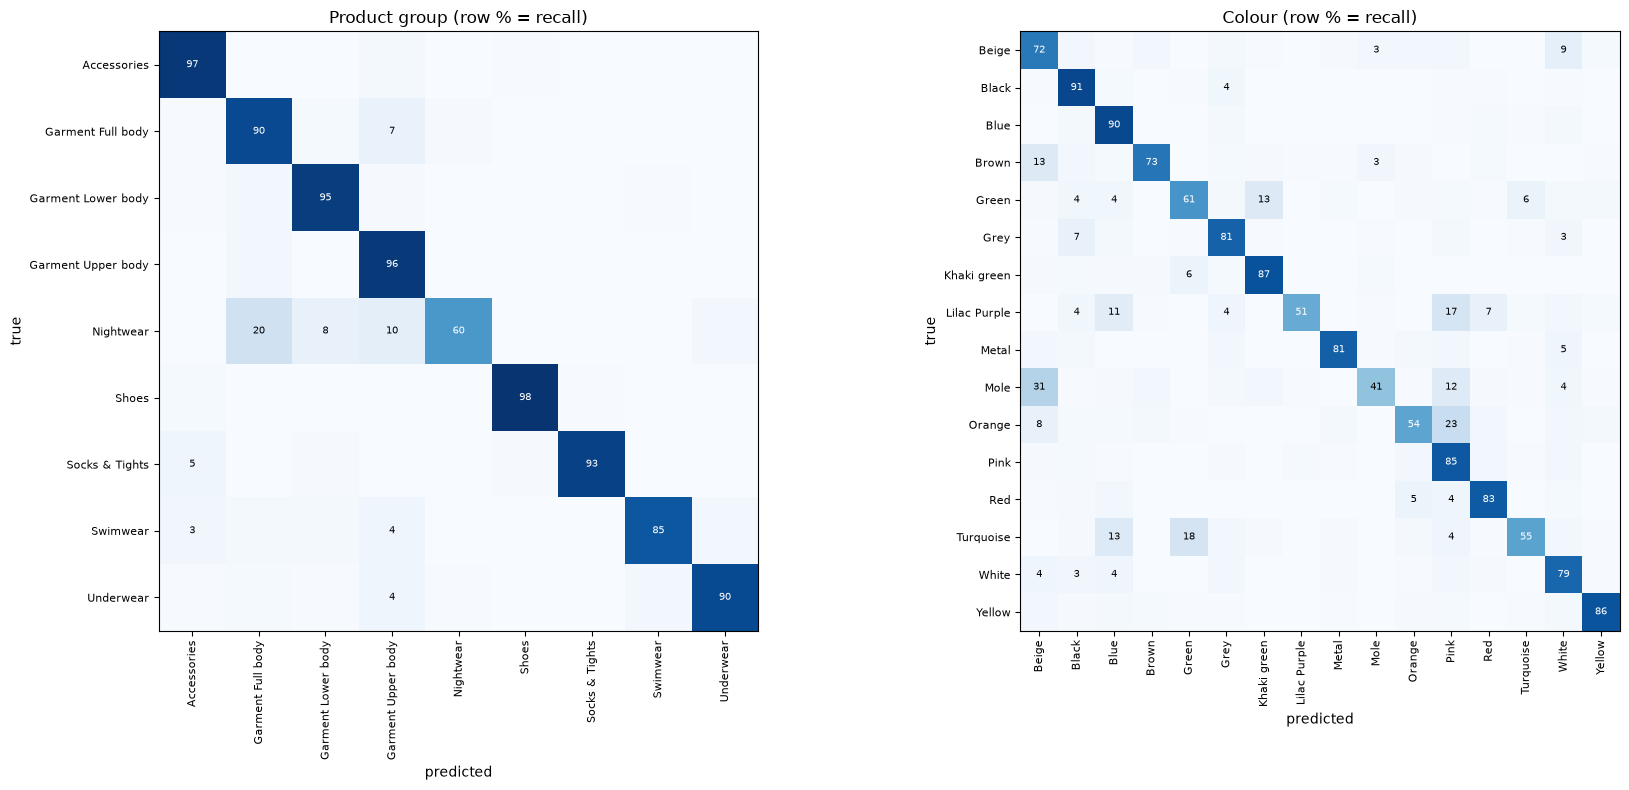


GROUP: most common confusions (% of the true class)
                  Nightwear -> Garment Full body         19.6%
                  Nightwear -> Garment Upper body        9.6%
                  Nightwear -> Garment Lower body        7.8%
          Garment Full body -> Garment Upper body        6.8%
             Socks & Tights -> Accessories               4.6%
                   Swimwear -> Garment Upper body        4.3%
                  Underwear -> Garment Upper body        4.1%
                   Swimwear -> Accessories               3.4%

COLOUR: most common confusions (% of the true class)
                       Mole -> Beige                     30.6%
                     Orange -> Pink                      23.3%
                  Turquoise -> Green                     17.9%
               Lilac Purple -> Pink                      16.6%
                  Turquoise -> Blue                      13.5%
                      Green -> Khaki green               13.1%
                  

In [4]:
from sklearn.metrics import confusion_matrix

def plot_cm(y, pred, names, ax, title):
    cm = confusion_matrix(y, pred, normalize="true")   # each row sums to 1
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(names)), names, rotation=90, fontsize=8)
    ax.set_yticks(range(len(names)), names, fontsize=8)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(title)
    for i in range(len(names)):
        for j in range(len(names)):
            if cm[i, j] >= 0.03:                        # only label cells >= 3%, to keep it readable
                ax.text(j, i, f"{cm[i, j] * 100:.0f}", ha="center", va="center", fontsize=7,
                        color="white" if cm[i, j] > 0.5 else "black")
    return cm

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
cm_g = plot_cm(y_g, pred_g, groups, axes[0], "Product group (row % = recall)")
cm_c = plot_cm(y_c, pred_c, colours, axes[1], "Colour (row % = recall)")
plt.tight_layout()
plt.savefig("../reports/figures/finetune_confusion.png", dpi=150)
plt.show()

for title, cm, names in [("GROUP", cm_g, groups), ("COLOUR", cm_c, colours)]:
    off = cm.copy()
    np.fill_diagonal(off, 0)                            # remove the correct answers, keep only mistakes
    flat = np.argsort(off.ravel())[::-1][:8]            # the 8 biggest mistake cells
    print(f"\n{title}: most common confusions (% of the true class)")
    for k in flat:
        i, j = np.unravel_index(k, off.shape)
        print(f"  {names[i]:>25} -> {names[j]:<25} {off[i, j] * 100:.1f}%")

In [5]:
import polars as pl

art = (pl.read_csv("../data/raw/articles.csv", columns=["article_id", "product_type_name"],
                   schema_overrides={"article_id": pl.Utf8})
         .with_columns(pl.col("article_id").str.zfill(10)))
ptype = dict(zip(art["article_id"], art["product_type_name"]))

JEWELLERY = {"Earring", "Earrings", "Necklace", "Ring", "Bracelet"}

def bucket(aid, g):
    t = ptype[aid]
    if t in JEWELLERY:
        return "Jewellery"
    if t == "Sunglasses":
        return "Sunglasses"
    if groups[g] == "Shoes":
        return "Shoes"
    if groups[g].startswith("Garment"):
        return "Garments"
    return "Other accessories"

b = np.array([bucket(aid, g) for aid, g in zip(val_ds.ids, y_g)])
METAL = colours.index("Metal")
is_metal, said_metal = (y_c == METAL), (pred_c == METAL)

print(f"{'bucket':<18}{'items':>7}{'% Metal':>9}{'Metal found':>16}{'non-Metal called Metal':>25}")
for name in ["Jewellery", "Sunglasses", "Shoes", "Garments", "Other accessories"]:
    m = b == name
    n_metal = (m & is_metal).sum()
    found = (m & is_metal & said_metal).sum() / max(n_metal, 1)
    false_alarm = (m & ~is_metal & said_metal).sum() / max((m & ~is_metal).sum(), 1)
    print(f"{name:<18}{m.sum():>7}{is_metal[m].mean() * 100:>8.0f}%{found * 100:>9.0f}% ({n_metal:>3}){false_alarm * 100:>20.1f}%")

bucket              items  % Metal     Metal found   non-Metal called Metal
Jewellery             313      69%       95% (215)                51.0%
Sunglasses             74       7%       40% (  5)                 7.2%
Shoes                 735       5%       51% ( 37)                 1.1%
Garments            10723       0%        0% ( 11)                 0.0%
Other accessories    3014       1%       64% ( 39)                 0.3%


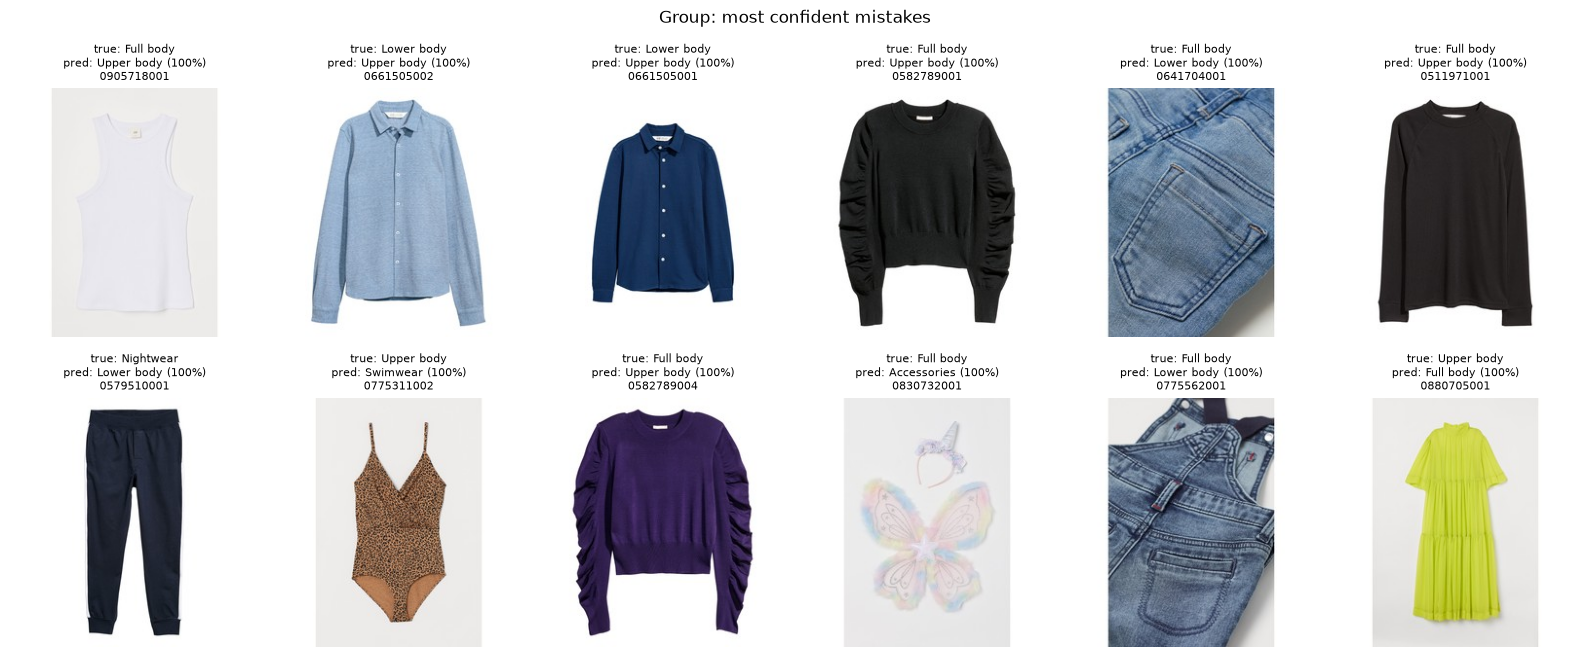

944 mistakes; 25% of them made with >90% confidence


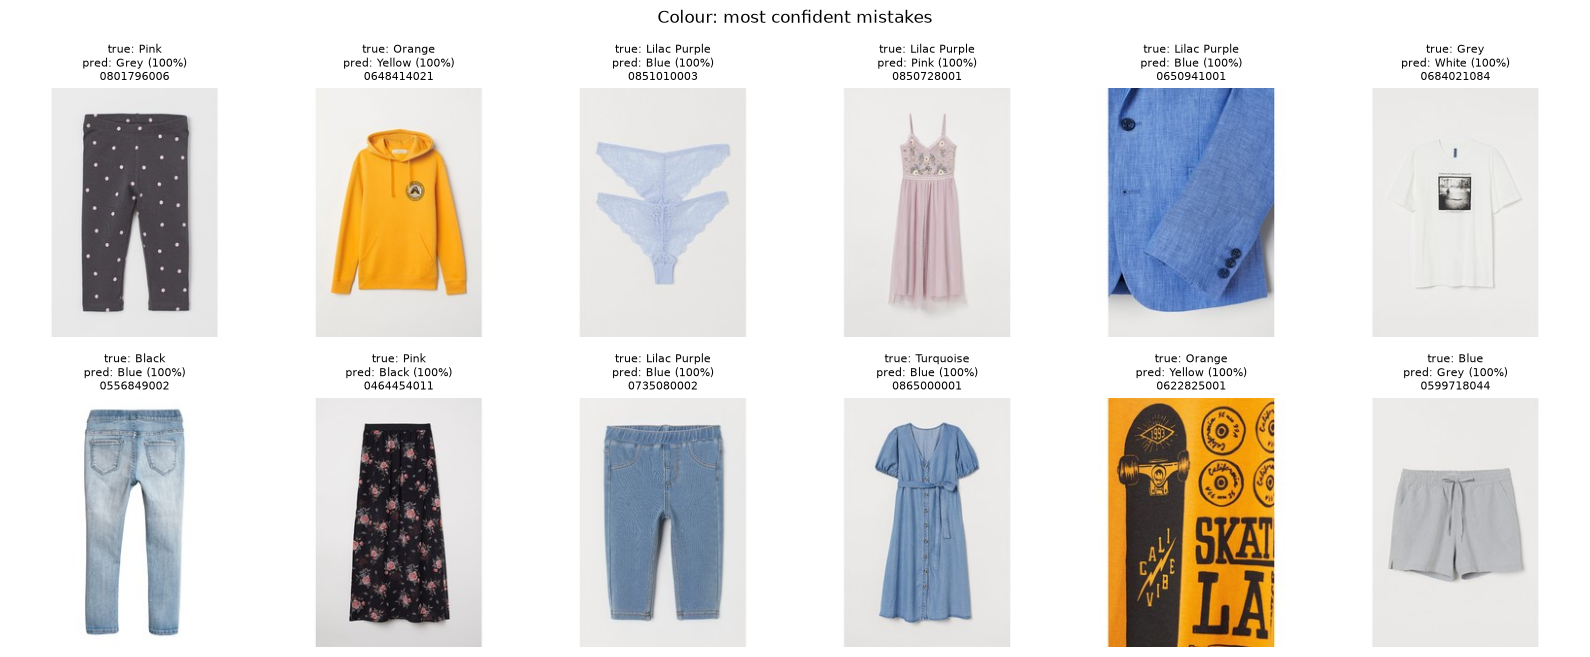

2,682 mistakes; 14% of them made with >90% confidence


In [6]:
from PIL import Image
from src.data.images import IMG_DIR

def error_gallery(P, y, names, title, fname, n=12):
    pred = P.argmax(1)
    conf = P.max(1)                                        # how sure it was about its answer
    wrong = np.where(pred != y)[0]                         # positions of all mistakes
    worst = wrong[np.argsort(conf[wrong])[::-1][:n]]       # the n most confident mistakes
    fig, axes = plt.subplots(2, 6, figsize=(16, 7))
    for ax, i in zip(axes.flat, worst):
        aid = val_ds.ids[i]
        ax.imshow(Image.open(IMG_DIR / aid[:3] / f"{aid}.jpg"))
        ax.set_title(f"true: {names[y[i]]}\npred: {names[pred[i]]} ({conf[i] * 100:.0f}%)\n{aid}", fontsize=8)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(f"../reports/figures/{fname}", dpi=150)
    plt.show()
    print(f"{len(wrong):,} mistakes; {(conf[wrong] > 0.9).mean() * 100:.0f}% of them made with >90% confidence")

error_gallery(P_g, y_g, [g.replace("Garment ", "") for g in groups], "Group: most confident mistakes", "errors_group.png")
error_gallery(P_c, y_c, colours, "Colour: most confident mistakes", "errors_colour.png")